Loading dataset...

Dataset loaded successfully!
Total documents: 1980
Classes: ['rec.autos', 'sci.med']

Class distribution:
0    990
1    990
Name: count, dtype: int64

Training documents: 1584
Testing documents: 396

Converting text into TF-IDF features...
Training feature shape: (1584, 10000)
Testing feature shape: (396, 10000)

Training and evaluating models...

Running: Decision Tree
Accuracy: 0.8207
Precision: 0.8226
Recall: 0.8207
F1-score: 0.8204

Running: KNN
Accuracy: 0.9015
Precision: 0.9023
Recall: 0.9015
F1-score: 0.9015

Running: SVM
Accuracy: 0.9217
Precision: 0.922
Recall: 0.9217
F1-score: 0.9217

Running: Naive Bayes
Accuracy: 0.9318
Precision: 0.9321
Recall: 0.9318
F1-score: 0.9318

========== COMPARATIVE RESULTS ==========


,Accuracy,Precision,Recall,F1-score,Training Time (s)
Model,,,,,
Decision Tree,0.8207,0.8226,0.8207,0.8204,0.2890
KNN,0.9015,0.9023,0.9015,0.9015,0.0015
SVM,0.9217,0.9220,0.9217,0.9217,0.0097
Naive Bayes,0.9318,0.9321,0.9318,0.9318,0.0027


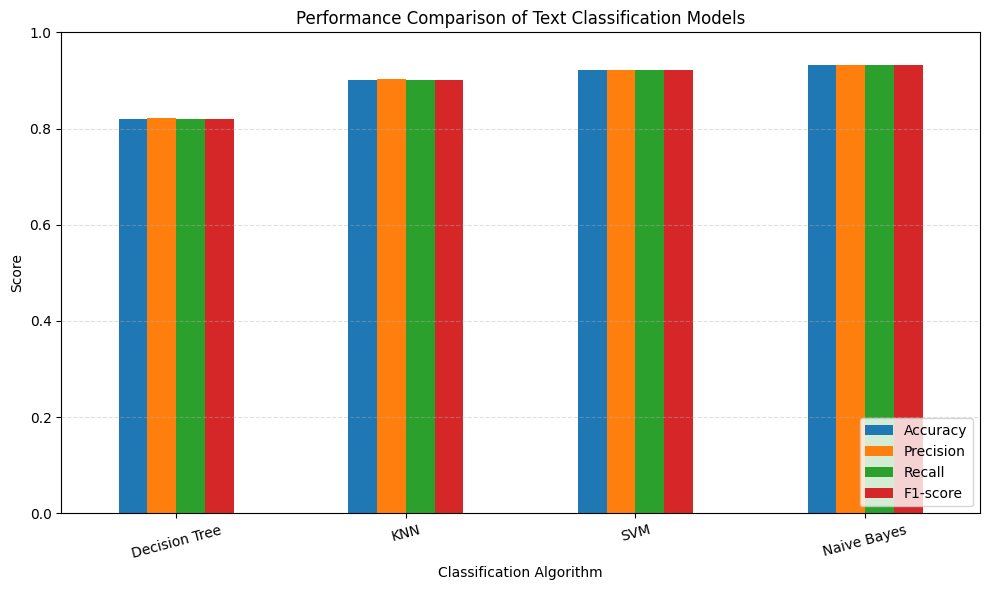


========== Decision Tree ==========

Classification Report:
              precision    recall  f1-score   support

   rec.autos       0.80      0.86      0.83       198
     sci.med       0.85      0.78      0.81       198

    accuracy                           0.82       396
   macro avg       0.82      0.82      0.82       396
weighted avg       0.82      0.82      0.82       396



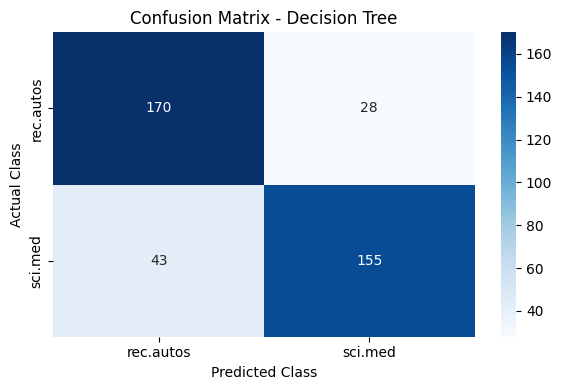


========== KNN ==========

Classification Report:
              precision    recall  f1-score   support

   rec.autos       0.92      0.88      0.90       198
     sci.med       0.88      0.92      0.90       198

    accuracy                           0.90       396
   macro avg       0.90      0.90      0.90       396
weighted avg       0.90      0.90      0.90       396



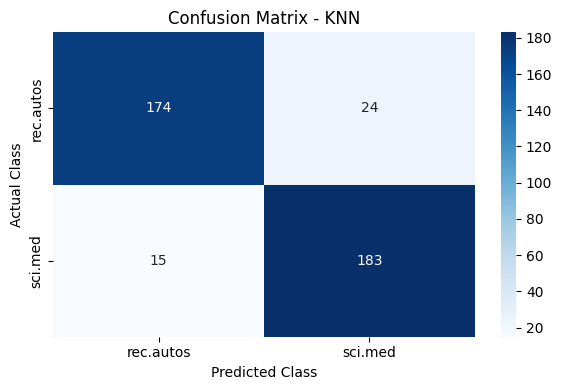


========== SVM ==========

Classification Report:
              precision    recall  f1-score   support

   rec.autos       0.91      0.93      0.92       198
     sci.med       0.93      0.91      0.92       198

    accuracy                           0.92       396
   macro avg       0.92      0.92      0.92       396
weighted avg       0.92      0.92      0.92       396



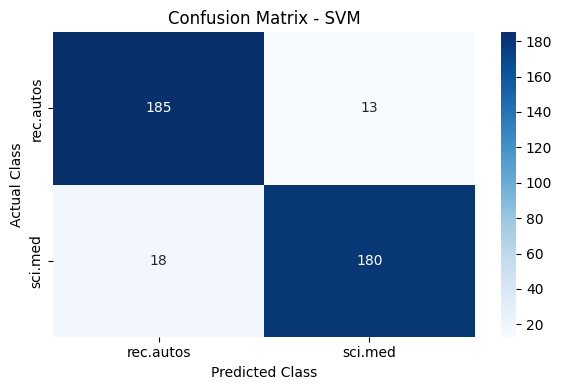


========== Naive Bayes ==========

Classification Report:
              precision    recall  f1-score   support

   rec.autos       0.92      0.94      0.93       198
     sci.med       0.94      0.92      0.93       198

    accuracy                           0.93       396
   macro avg       0.93      0.93      0.93       396
weighted avg       0.93      0.93      0.93       396



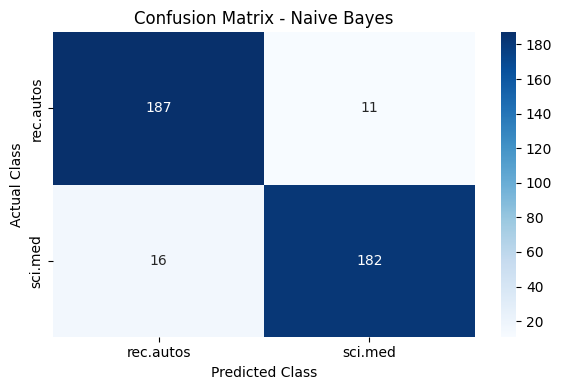


Best-performing model based on macro F1-score:
Naive Bayes

Best model metrics:
Accuracy             0.9318
Precision            0.9321
Recall               0.9318
F1-score             0.9318
Training Time (s)    0.0027
Name: Naive Bayes, dtype: float64

========== WHAT-IF EXPERIMENT ==========
Experiment: Changing SVM kernel from linear to RBF

Original Linear SVM:
Accuracy             0.9217
Precision            0.9220
Recall               0.9217
F1-score             0.9217
Training Time (s)    0.0097
Name: SVM, dtype: float64

RBF SVM:
Accuracy             0.9318
Precision            0.9321
Recall               0.9318
F1-score             0.9318
Training Time (s)    1.1205
dtype: float64

SVM Comparison:


,Linear SVM,RBF SVM
Accuracy,0.9217,0.9318
Precision,0.9220,0.9321
Recall,0.9217,0.9318
F1-score,0.9217,0.9318
Training Time (s),0.0097,1.1205



Experiment completed successfully!
Results saved as classification_results.csv


In [2]:

# ============================================================
# TEXT CLASSIFICATION COMPARISON
# Decision Tree, KNN, SVM, and Naive Bayes
# ============================================================

# 1. IMPORT LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 2. LOAD DATASET
print("Loading dataset...")

categories = ['rec.autos', 'sci.med']

data = fetch_20newsgroups(
    subset='all',
    categories=categories,
    remove=('headers', 'footers', 'quotes'),
    shuffle=True,
    random_state=42
)

X_text = data.data
y = data.target

print("\nDataset loaded successfully!")
print("Total documents:", len(X_text))
print("Classes:", data.target_names)

print("\nClass distribution:")
print(pd.Series(y).value_counts().sort_index())

# 3. SPLIT DATASET
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining documents:", len(X_train_text))
print("Testing documents:", len(X_test_text))

# 4. TEXT PREPROCESSING AND TF-IDF
print("\nConverting text into TF-IDF features...")

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words='english',
    ngram_range=(1, 2),
    max_features=10000,
    sublinear_tf=True
)

X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

# 5. DEFINE CLASSIFIERS
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=100,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric='cosine',
        algorithm='brute'
    ),

    "SVM": LinearSVC(
        random_state=42
    ),

    "Naive Bayes": MultinomialNB()
}

# 6. TRAIN AND EVALUATE MODELS
results = []
predictions = {}
training_times = {}

print("\nTraining and evaluating models...")

for name, model in models.items():

    print("\nRunning:", name)

    start_time = time.time()
    model.fit(X_train, y_train)
    training_times[name] = time.time() - start_time

    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred,
        average='macro',
        zero_division=0
    )
    recall = recall_score(
        y_test, y_pred,
        average='macro',
        zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred,
        average='macro',
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Training Time (s)": training_times[name]
    })

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-score:", round(f1, 4))

# 7. COMPARATIVE RESULTS TABLE
results_df = pd.DataFrame(results).set_index("Model")

print("\n========== COMPARATIVE RESULTS ==========")
display(results_df.round(4))

# 8. PERFORMANCE COMPARISON GRAPH
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

results_df[metrics].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Performance Comparison of Text Classification Models")
plt.ylabel("Score")
plt.xlabel("Classification Algorithm")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# 9. CONFUSION MATRICES
for name, y_pred in predictions.items():

    cm = confusion_matrix(y_test, y_pred)

    print("\n==========", name, "==========")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=data.target_names,
        zero_division=0
    ))

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=data.target_names,
        yticklabels=data.target_names
    )

    plt.title("Confusion Matrix - " + name)
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.show()

# 10. IDENTIFY BEST MODEL
best_model = results_df['F1-score'].idxmax()

print("\nBest-performing model based on macro F1-score:")
print(best_model)

print("\nBest model metrics:")
print(results_df.loc[best_model].round(4))

# 11. WHAT-IF EXPERIMENT
# Change SVM from a linear kernel to an RBF kernel

print("\n========== WHAT-IF EXPERIMENT ==========")
print("Experiment: Changing SVM kernel from linear to RBF")

rbf_svm = SVC(
    kernel='rbf',
    C=1.0
)

start_time = time.time()
rbf_svm.fit(X_train, y_train)
rbf_training_time = time.time() - start_time

rbf_pred = rbf_svm.predict(X_test)

rbf_results = {
    "Accuracy": accuracy_score(y_test, rbf_pred),
    "Precision": precision_score(
        y_test, rbf_pred,
        average='macro',
        zero_division=0
    ),
    "Recall": recall_score(
        y_test, rbf_pred,
        average='macro',
        zero_division=0
    ),
    "F1-score": f1_score(
        y_test, rbf_pred,
        average='macro',
        zero_division=0
    ),
    "Training Time (s)": rbf_training_time
}

print("\nOriginal Linear SVM:")
print(results_df.loc["SVM"].round(4))

print("\nRBF SVM:")
print(pd.Series(rbf_results).round(4))

# Compare linear and RBF SVM
svm_comparison = pd.DataFrame({
    "Linear SVM": results_df.loc["SVM"],
    "RBF SVM": pd.Series(rbf_results)
})

print("\nSVM Comparison:")
display(svm_comparison.round(4))

# 12. SAVE RESULTS
results_df.to_csv("classification_results.csv")

print("\nExperiment completed successfully!")
print("Results saved as classification_results.csv")
